In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

sns.set_style("whitegrid")

# Load dataset
df = pd.read_csv("../dataset/StudentPerformanceFactors.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [2]:
X = df.drop(columns=["Exam_Score"])
y = df["Exam_Score"]

print("Input features:", X.shape)
print("Target variable:", y.shape)

Input features: (6607, 19)
Target variable: (6607,)


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 5285
Testing records: 1322


In [4]:
numerical_columns = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    include=["object", "str"]
).columns.tolist()

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combined preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_columns),
    ("cat", categorical_transformer, categorical_columns)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [5]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

print("Four regression models defined successfully!")

Four regression models defined successfully!


In [6]:
results = []

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=5,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "MAE": -scores["test_mae"].mean(),
        "RMSE": -scores["test_rmse"].mean(),
        "R2": scores["test_r2"].mean()
    })

results_df = pd.DataFrame(results).sort_values(
    by="RMSE",
    ascending=True
)

display(results_df)

,Model,MAE,RMSE,R2
0,Linear Regression,0.507147,2.052512,0.723193
3,Gradient Boosting,0.847544,2.192777,0.685599
2,Random Forest,1.172660,2.399038,0.624575
1,Decision Tree,1.936991,3.864497,0.024772


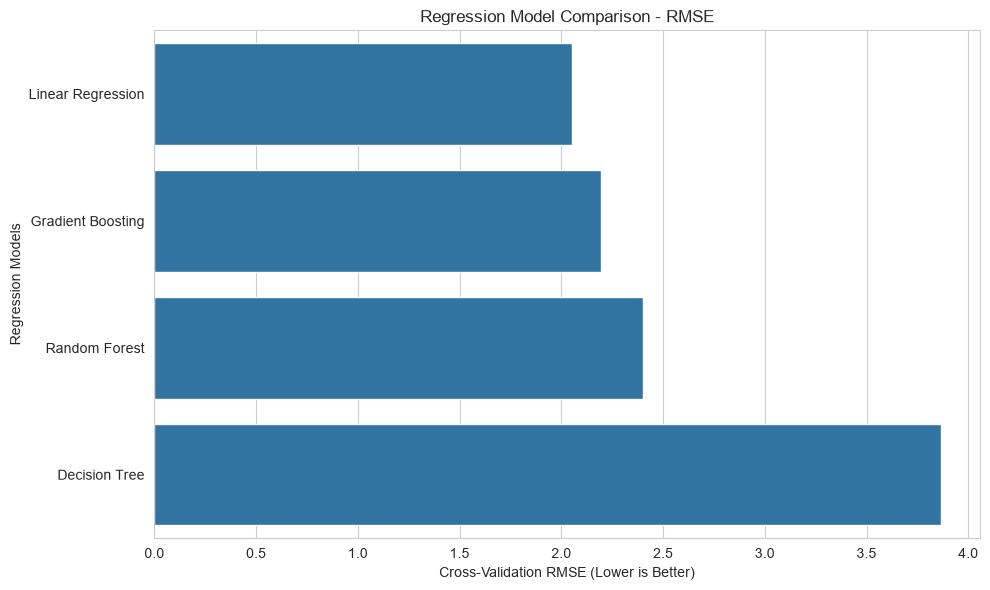

In [7]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="RMSE",
    y="Model"
)

plt.title("Regression Model Comparison - RMSE")
plt.xlabel("Cross-Validation RMSE (Lower is Better)")
plt.ylabel("Regression Models")

plt.tight_layout()
plt.show()

In [8]:
# Create the best model pipeline

best_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

# Train the model

best_model.fit(X_train, y_train)

print("Linear Regression trained successfully!")

Linear Regression trained successfully!


In [9]:
# Generate predictions

y_pred = best_model.predict(X_test)

# Calculate evaluation metrics

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Linear Regression Test Results")
print("--------------------------------")
print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))

Linear Regression Test Results
--------------------------------
MAE: 0.4524
MSE: 3.256
RMSE: 1.8044
R2 Score: 0.7696


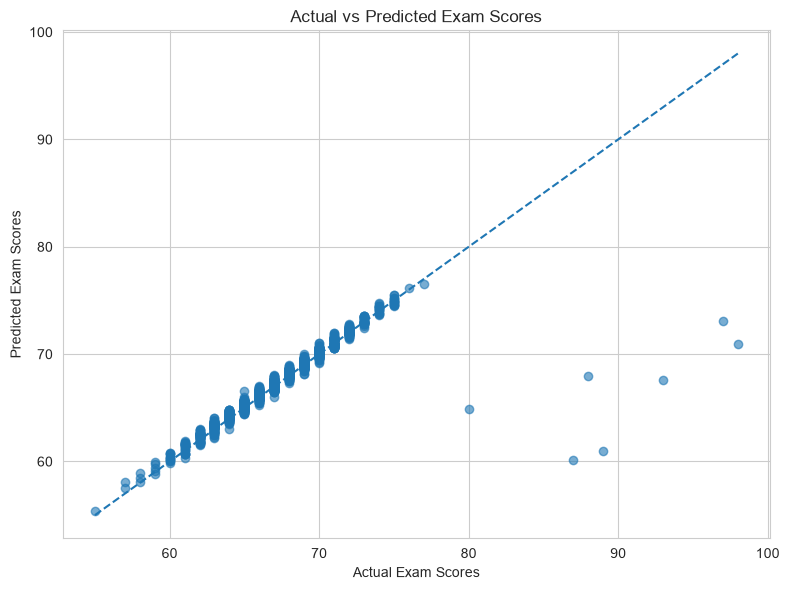

In [10]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Exam Scores")
plt.ylabel("Predicted Exam Scores")

plt.title("Actual vs Predicted Exam Scores")

plt.tight_layout()
plt.show()

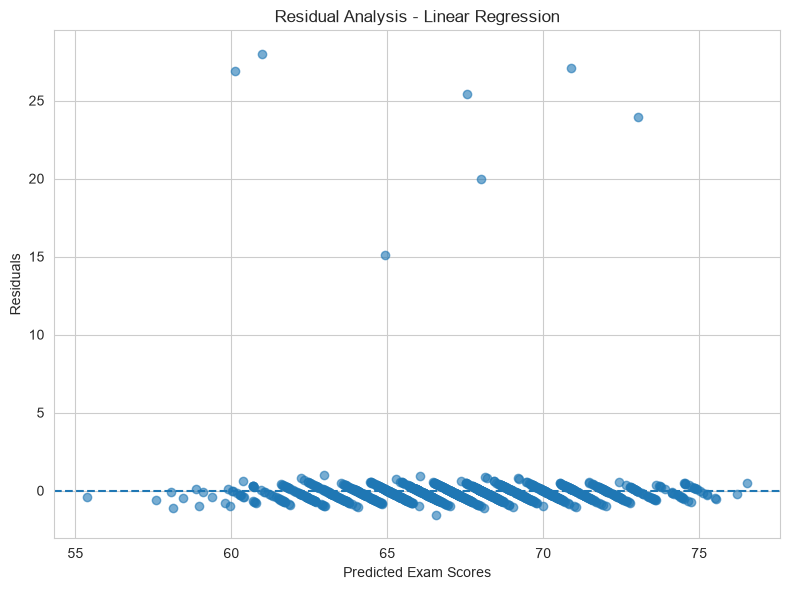

In [11]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.6
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Exam Scores")
plt.ylabel("Residuals")

plt.title("Residual Analysis - Linear Regression")

plt.tight_layout()
plt.show()

In [12]:
# Create prediction comparison dataframe

error_analysis = pd.DataFrame({
    "Actual_Score": y_test.values,
    "Predicted_Score": y_pred
})

# Calculate residual and absolute error

error_analysis["Residual"] = (
    error_analysis["Actual_Score"] -
    error_analysis["Predicted_Score"]
)

error_analysis["Absolute_Error"] = (
    error_analysis["Residual"].abs()
)

# Display largest prediction errors

error_analysis = error_analysis.sort_values(
    by="Absolute_Error",
    ascending=False
)

display(error_analysis.head(15))

,Actual_Score,Predicted_Score,Residual,Absolute_Error
28,89,60.989759,28.010241,28.010241
704,98,70.902730,27.097270,27.097270
1125,87,60.105764,26.894236,26.894236
1144,93,67.554328,25.445672,25.445672
721,97,73.039858,23.960142,23.960142
480,88,68.007096,19.992904,19.992904
945,80,64.929614,15.070386,15.070386
448,65,66.570881,-1.570881,1.570881
493,57,58.119570,-1.119570,1.119570
340,67,68.098534,-1.098534,1.098534


In [13]:
# Identify students with actual scores above 80

high_score_errors = error_analysis[
    error_analysis["Actual_Score"] > 80
]

print("Number of high-scoring students in test set:",
      len(high_score_errors))

display(high_score_errors)

Number of high-scoring students in test set: 6


,Actual_Score,Predicted_Score,Residual,Absolute_Error
28,89,60.989759,28.010241,28.010241
704,98,70.902730,27.097270,27.097270
1125,87,60.105764,26.894236,26.894236
1144,93,67.554328,25.445672,25.445672
721,97,73.039858,23.960142,23.960142
480,88,68.007096,19.992904,19.992904


In [14]:
print("Residual Statistics")
print("-------------------")

print("Mean Residual:",
      round(error_analysis["Residual"].mean(), 4))

print("Maximum Residual:",
      round(error_analysis["Residual"].max(), 4))

print("Minimum Residual:",
      round(error_analysis["Residual"].min(), 4))

print("Mean Absolute Error:",
      round(error_analysis["Absolute_Error"].mean(), 4))

Residual Statistics
-------------------
Mean Residual: -0.0492
Maximum Residual: 28.0102
Minimum Residual: -1.5709
Mean Absolute Error: 0.4524


In [15]:
# Rebuild error analysis while preserving original row indexes

error_analysis = pd.DataFrame({
    "Actual_Score": y_test,
    "Predicted_Score": y_pred
}, index=y_test.index)

error_analysis["Residual"] = (
    error_analysis["Actual_Score"] -
    error_analysis["Predicted_Score"]
)

error_analysis["Absolute_Error"] = (
    error_analysis["Residual"].abs()
)

# Select the 7 largest prediction errors

worst_predictions = error_analysis.nlargest(
    7,
    "Absolute_Error"
)

# Retrieve the original student features

worst_students = X_test.loc[
    worst_predictions.index
].copy()

worst_students["Actual_Score"] = (
    worst_predictions["Actual_Score"]
)

worst_students["Predicted_Score"] = (
    worst_predictions["Predicted_Score"]
)

worst_students["Absolute_Error"] = (
    worst_predictions["Absolute_Error"]
)

display(worst_students)

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,...,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Actual_Score,Predicted_Score,Absolute_Error
217,19,70,Medium,Low,No,7,54,High,Yes,0,...,Public,Positive,2,Yes,High School,Moderate,Male,89,60.989759,28.010241
4192,28,90,Low,Medium,Yes,9,91,Medium,Yes,0,...,Public,Positive,2,No,College,Moderate,Female,98,70.902730,27.097270
2687,11,71,Low,Medium,Yes,8,55,Medium,Yes,1,...,Public,Negative,3,No,College,Near,Female,87,60.105764,26.894236
4531,26,69,High,High,No,7,95,Low,No,0,...,Public,Negative,3,No,Postgraduate,Near,Female,93,67.554328,25.445672
5966,25,99,Medium,Medium,Yes,7,77,Medium,Yes,0,...,Public,Neutral,3,No,High School,Near,Male,97,73.039858,23.960142
2513,18,86,High,Medium,No,8,60,Medium,Yes,2,...,Private,Neutral,1,No,College,Near,Male,88,68.007096,19.992904
5989,18,61,Medium,Low,Yes,6,91,High,Yes,3,...,Public,Positive,3,No,College,Moderate,Female,80,64.929614,15.070386


In [16]:
# Analyse examination score distribution

print("Examination Score Distribution")
print("--------------------------------")

print("Scores above 75:",
      (df["Exam_Score"] > 75).sum())

print("Scores above 80:",
      (df["Exam_Score"] > 80).sum())

print("Scores above 85:",
      (df["Exam_Score"] > 85).sum())

print("Scores above 90:",
      (df["Exam_Score"] > 90).sum())

print("Scores above 95:",
      (df["Exam_Score"] > 95).sum())

Examination Score Distribution
--------------------------------
Scores above 75: 76
Scores above 80: 43
Scores above 85: 34
Scores above 90: 22
Scores above 95: 11


In [17]:
# Compare high-error students with the full dataset

comparison = pd.DataFrame({
    "Full Dataset Mean": df[
        ["Hours_Studied", "Attendance", "Previous_Scores", "Exam_Score"]
    ].mean(),

    "High Error Students Mean": worst_students[
        ["Hours_Studied", "Attendance", "Previous_Scores", "Actual_Score"]
    ].mean()
})

comparison.columns = [
    "Full Dataset Mean",
    "High Error Students Mean"
]

display(comparison)

,Full Dataset Mean,High Error Students Mean
Actual_Score,NaN,90.285714
Attendance,79.977448,78.000000
Exam_Score,67.235659,NaN
Hours_Studied,19.975329,20.714286
Previous_Scores,75.070531,74.714286


In [18]:
# Analyse high scores in training and testing data

print("HIGH-SCORE DISTRIBUTION")
print("-----------------------")

for threshold in [75, 80, 85, 90, 95]:

    train_count = (y_train > threshold).sum()
    test_count = (y_test > threshold).sum()

    print(f"\nScores above {threshold}:")
    print("Training records:", train_count)
    print("Testing records:", test_count)

HIGH-SCORE DISTRIBUTION
-----------------------

Scores above 75:
Training records: 67
Testing records: 9

Scores above 80:
Training records: 37
Testing records: 6

Scores above 85:
Training records: 28
Testing records: 6

Scores above 90:
Training records: 19
Testing records: 3

Scores above 95:
Training records: 9
Testing records: 2


In [19]:
# Correlation with examination score

correlation = df[
    ["Hours_Studied", "Attendance",
     "Previous_Scores", "Exam_Score"]
].corr()

print(correlation["Exam_Score"].sort_values(ascending=False))

Exam_Score         1.000000
Attendance         0.581072
Hours_Studied      0.445455
Previous_Scores    0.175079
Name: Exam_Score, dtype: float64


In [20]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_validate

In [21]:
# Numerical preprocessing with polynomial features

polynomial_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("polynomial", PolynomialFeatures(
        degree=2,
        include_bias=False
    )),
    ("scaler", StandardScaler())
])

# Categorical preprocessing

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both transformers

polynomial_preprocessor = ColumnTransformer(
    transformers=[
        ("num", polynomial_transformer, numerical_columns),
        ("cat", categorical_transformer, categorical_columns)
    ]
)

print("Polynomial preprocessing pipeline created!")

Polynomial preprocessing pipeline created!


In [22]:
polynomial_model = Pipeline(steps=[
    ("preprocessor", polynomial_preprocessor),
    ("model", Ridge(alpha=1.0))
])

print("Polynomial Regression model created!")

Polynomial Regression model created!


In [23]:
polynomial_scores = cross_validate(
    polynomial_model,
    X_train,
    y_train,
    cv=5,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    },
    n_jobs=-1
)

polynomial_results = {
    "Model": "Polynomial Regression",
    "MAE": -polynomial_scores["test_mae"].mean(),
    "RMSE": -polynomial_scores["test_rmse"].mean(),
    "R2": polynomial_scores["test_r2"].mean()
}

print("Polynomial Regression Results")
print("--------------------------------")
print(polynomial_results)

Polynomial Regression Results
--------------------------------
{'Model': 'Polynomial Regression', 'MAE': np.float64(0.5294751623607425), 'RMSE': np.float64(2.0567002344978134), 'R2': np.float64(0.7221302383322803)}


In [24]:
comparison_df = pd.concat(
    [
        results_df,
        pd.DataFrame([polynomial_results])
    ],
    ignore_index=True
)

comparison_df = comparison_df.sort_values(
    by="RMSE",
    ascending=True
)

display(comparison_df)

,Model,MAE,RMSE,R2
0,Linear Regression,0.507147,2.052512,0.723193
4,Polynomial Regression,0.529475,2.056700,0.722130
1,Gradient Boosting,0.847544,2.192777,0.685599
2,Random Forest,1.172660,2.399038,0.624575
3,Decision Tree,1.936991,3.864497,0.024772


In [25]:
from sklearn.linear_model import Ridge

In [26]:
from sklearn.model_selection import cross_validate

ridge_alphas = [0.01, 0.1, 1, 10, 100]

ridge_results = []

for alpha in ridge_alphas:

    ridge_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", Ridge(alpha=alpha))
    ])

    scores = cross_validate(
        ridge_pipeline,
        X_train,
        y_train,
        cv=5,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=-1
    )

    ridge_results.append({
        "Alpha": alpha,
        "MAE": -scores["test_mae"].mean(),
        "RMSE": -scores["test_rmse"].mean(),
        "R2": scores["test_r2"].mean()
    })

ridge_results_df = pd.DataFrame(ridge_results)

display(ridge_results_df)

,Alpha,MAE,RMSE,R2
0,0.01,0.507147,2.052512,0.723193
1,0.10,0.507143,2.052510,0.723194
2,1.00,0.507112,2.052492,0.723199
3,10.00,0.507010,2.052375,0.723229
4,100.00,0.523556,2.056466,0.722164


In [27]:
best_ridge_result = ridge_results_df.loc[
    ridge_results_df["RMSE"].idxmin()
]

print("Best Ridge Regression configuration:")
print(best_ridge_result)

Best Ridge Regression configuration:
Alpha    10.000000
MAE       0.507010
RMSE      2.052375
R2        0.723229
Name: 3, dtype: float64


In [28]:
ridge_comparison = pd.concat(
    [
        results_df,
        pd.DataFrame([{
            "Model": f"Ridge Regression (alpha={best_ridge_result['Alpha']})",
            "MAE": best_ridge_result["MAE"],
            "RMSE": best_ridge_result["RMSE"],
            "R2": best_ridge_result["R2"]
        }])
    ],
    ignore_index=True
)

display(
    ridge_comparison.sort_values(
        by="RMSE",
        ascending=True
    )
)

,Model,MAE,RMSE,R2
4,Ridge Regression (alpha=10.0),0.507010,2.052375,0.723229
0,Linear Regression,0.507147,2.052512,0.723193
1,Gradient Boosting,0.847544,2.192777,0.685599
2,Random Forest,1.172660,2.399038,0.624575
3,Decision Tree,1.936991,3.864497,0.024772


In [29]:
import joblib
import os

# Define the best model
best_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=10))
])

# Train the model using training data
best_model.fit(X_train, y_train)

# Create models directory if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save the trained model
joblib.dump(best_model, "../models/best_model.pkl")

print("Best Ridge Regression model saved successfully!")

Best Ridge Regression model saved successfully!


In [30]:
loaded_model = joblib.load("../models/best_model.pkl")

print("Model loaded successfully!")
print("Model type:", type(loaded_model))

Model loaded successfully!
Model type: <class 'sklearn.pipeline.Pipeline'>
